# Book Recommender System using a Medallion Data Lake (Bronze → Silver → Gold)
Dataset: Book-Crossing (Users, Books, Book-Ratings)

## Step 1: Set up the data lake and build the Bronze layer

In [1]:
import os, zipfile, html, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

for d in ['bronze', 'silver', 'gold', 'raw']:
    os.makedirs(d, exist_ok=True)

# Download the raw zip (or upload book-crossings.zip to Colab)
if not os.path.exists('book-crossings.zip'):
    !wget -q https://cdn.freecodecamp.org/project-data/books/book-crossings.zip
with zipfile.ZipFile('book-crossings.zip') as z:
    z.extractall('raw')
print(os.listdir('raw'))

['BX-Book-Ratings.csv', 'BX-Users.csv', 'BX-Books.csv']


In [2]:
# Files use ';' separator and latin-1 (non-UTF-8) encoding. Load everything as text, no cleaning.
read_opts = dict(sep=';', encoding='latin-1', dtype=str, escapechar='\\', on_bad_lines='skip')
users_raw   = pd.read_csv('raw/BX-Users.csv', **read_opts)
books_raw   = pd.read_csv('raw/BX-Books.csv', **read_opts)
ratings_raw = pd.read_csv('raw/BX-Book-Ratings.csv', **read_opts)

ts = pd.Timestamp.now()
for name, df in [('users', users_raw), ('books', books_raw), ('ratings', ratings_raw)]:
    df['ingestion_timestamp'] = ts
    df.to_parquet(f'bronze/{name}.parquet', index=False)
    print(name, df.shape)

users (278858, 4)
books (271379, 9)
ratings (1149780, 4)


## Step 2: Explore the Bronze data (EDA)

In [3]:
users = pd.read_parquet('bronze/users.parquet')
books = pd.read_parquet('bronze/books.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')
for name, df in [('users', users), ('books', books), ('ratings', ratings)]:
    print(f'--- {name}: shape {df.shape}')
    print(df.dtypes.to_string())
    print('missing:\n', df.isna().sum().to_string(), '\n')

--- users: shape (278858, 4)
User-ID                        object
Location                       object
Age                            object
ingestion_timestamp    datetime64[us]
missing:
 User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0 

--- books: shape (271379, 9)
ISBN                           object
Book-Title                     object
Book-Author                    object
Year-Of-Publication            object
Publisher                      object
Image-URL-S                    object
Image-URL-M                    object
Image-URL-L                    object
ingestion_timestamp    datetime64[us]
missing:
 ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0 

--- ratings: shape (1149780, 4)
User-ID                        object
ISBN     

**Finding:** All columns are loaded as text (object) and Age has many missing values. **Silver:** convert Age, Year and Rating to numbers and handle the nulls.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64
Zero ratings: 716109 (62.3%)


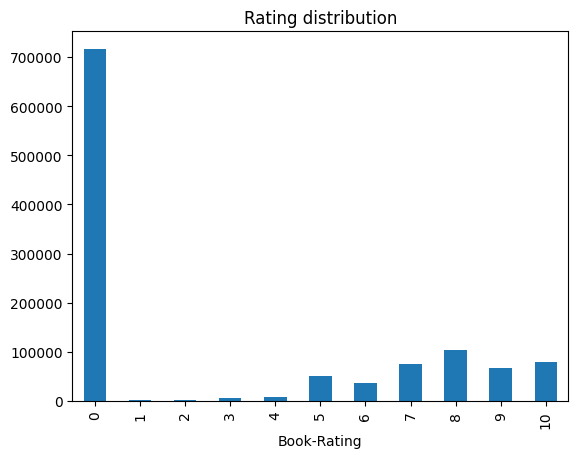

In [4]:
r = pd.to_numeric(ratings['Book-Rating'], errors='coerce')
print(r.value_counts().sort_index())
print(f'Zero ratings: {(r==0).sum()} ({(r==0).mean()*100:.1f}%)')
r.value_counts().sort_index().plot(kind='bar', title='Rating distribution'); plt.show()

**Finding:** About 62% of ratings are 0, which means 'no explicit rating'. **Silver:** remove ratings of 0 and keep only 1-10.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Ages <5 or >100: 1248
Years ==0: 4619 | future years: 11


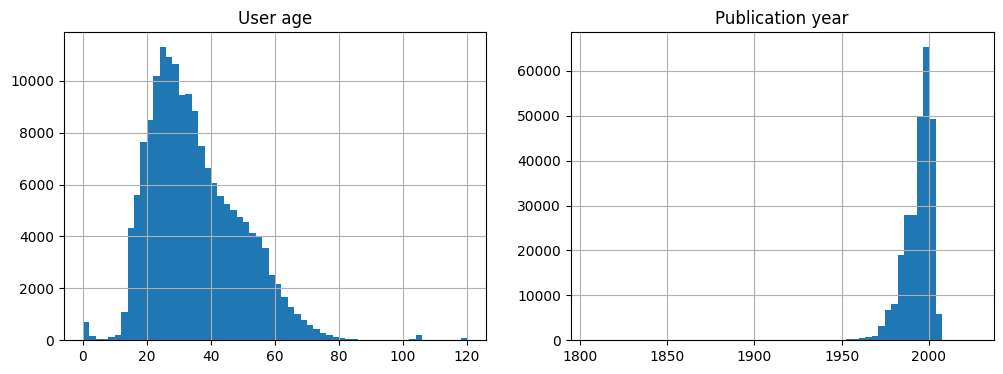

In [5]:
age = pd.to_numeric(users['Age'], errors='coerce')
year = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
print(age.describe()); print(year.describe())
print('Ages <5 or >100:', ((age<5)|(age>100)).sum())
print('Years ==0:', (year==0).sum(), '| future years:', (year>datetime.now().year).sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
age.dropna().clip(0, 120).hist(bins=60, ax=ax[0]); ax[0].set_title('User age')
year[(year>1800)&(year<2030)].hist(bins=60, ax=ax[1]); ax[1].set_title('Publication year')
plt.show()

**Finding:** Ages include impossible values (0 and above 200), and years include 0 and future years. **Silver:** set ages <5 or >100 to null and fill with the median, and set year 0 or future years to null.

In [6]:
per_user = ratings.groupby('User-ID').size()
per_book = ratings.groupby('ISBN').size()
print('Ratings per user:\n', per_user.describe())
print('Ratings per book:\n', per_book.describe())
print('Users with 1 rating:', (per_user==1).sum(), '| Books with 1 rating:', (per_book==1).sum())

Ratings per user:
 count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64
Ratings per book:
 count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64
Users with 1 rating: 59166 | Books with 1 rating: 197045


**Finding:** Most users and books have very few ratings (median about 1). **Silver:** keep only users and books with at least a minimum number of ratings.

In [7]:
n_u, n_b, n_r = ratings['User-ID'].nunique(), ratings['ISBN'].nunique(), len(ratings)
print(f'Sparsity: {(1 - n_r/(n_u*n_b))*100:.5f}% of user-book pairs are empty')

Sparsity: 99.99679% of user-book pairs are empty


**Finding:** The matrix is over 99.99% empty. **Gold:** store it as a sparse matrix.

## Step 3: Clean the data and build the Silver layer

In [8]:
users = pd.read_parquet('bronze/users.parquet').drop(columns='ingestion_timestamp')
books = pd.read_parquet('bronze/books.parquet').drop(columns='ingestion_timestamp')
ratings = pd.read_parquet('bronze/ratings.parquet').drop(columns='ingestion_timestamp')

# 1. Remove duplicates
users = users.drop_duplicates().drop_duplicates(subset='User-ID')
books['ISBN'] = books['ISBN'].str.strip().str.upper()
books = books.drop_duplicates().drop_duplicates(subset='ISBN')
ratings['ISBN'] = ratings['ISBN'].str.strip().str.upper()
ratings = ratings.drop_duplicates(subset=['User-ID', 'ISBN'])

# 2. Keep explicit ratings 1-10 only
ratings['Book-Rating'] = pd.to_numeric(ratings['Book-Rating'], errors='coerce')
ratings = ratings[ratings['Book-Rating'].between(1, 10)].copy()
ratings['Book-Rating'] = ratings['Book-Rating'].astype(int)

# 3. Fix ages
users['Age'] = pd.to_numeric(users['Age'], errors='coerce')
users.loc[(users['Age'] < 5) | (users['Age'] > 100), 'Age'] = np.nan
users['Age'] = users['Age'].fillna(users['Age'].median()).astype(int)

# 4. Split location into city, state, country
loc = users['Location'].fillna('').str.lower().str.rsplit(',', n=2, expand=True)
users['city'], users['state'], users['country'] = loc[0].str.strip(), loc[1].str.strip(), loc[2].str.strip()
users[['city', 'state', 'country']] = users[['city', 'state', 'country']].replace(['', 'n/a'], np.nan)
users = users.drop(columns='Location')

# 5. Fix publication years
books['Year-Of-Publication'] = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
books.loc[(books['Year-Of-Publication'] == 0) | (books['Year-Of-Publication'] > datetime.now().year), 'Year-Of-Publication'] = np.nan
books['Year-Of-Publication'] = books['Year-Of-Publication'].astype('Int64')

# 6. Clean text columns and drop image URLs
books = books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'])
for c in ['Book-Title', 'Book-Author', 'Publisher']:
    books[c] = books[c].fillna('').map(html.unescape).str.replace(r'\s+', ' ', regex=True).str.strip()
books['Book-Author'] = books['Book-Author'].str.title()
books['Publisher'] = books['Publisher'].str.title()

# 7. Keep ratings whose user and book exist
ratings = ratings[ratings['User-ID'].isin(users['User-ID']) & ratings['ISBN'].isin(books['ISBN'])]
print('Explicit ratings with valid user and book:', len(ratings))

Explicit ratings with valid user and book: 383853


**Threshold choice:** EDA showed most users and books have only 1-2 ratings, which gives no useful similarity signal.
I keep **users with at least 10 ratings** and **books with at least 10 ratings**, applied repeatedly until stable (removing books can drop a user below 10).
This keeps a dense core that is still large enough to give varied recommendations.

In [9]:
MIN_USER, MIN_BOOK = 10, 10
while True:
    before = len(ratings)
    bc = ratings['ISBN'].value_counts();    ratings = ratings[ratings['ISBN'].isin(bc[bc >= MIN_BOOK].index)]
    uc = ratings['User-ID'].value_counts(); ratings = ratings[ratings['User-ID'].isin(uc[uc >= MIN_USER].index)]
    if len(ratings) == before: break
users = users[users['User-ID'].isin(ratings['User-ID'])]
books = books[books['ISBN'].isin(ratings['ISBN'])]
print('ratings', ratings.shape, '| users', users.shape, '| books', books.shape)

users.to_parquet('silver/users.parquet', index=False)
books.to_parquet('silver/books.parquet', index=False)
ratings.to_parquet('silver/ratings.parquet', index=False)

ratings (41469, 3) | users (1820, 5) | books (2030, 5)


## Step 4: Build the Gold layer

In [10]:
ratings = pd.read_parquet('silver/ratings.parquet')
books = pd.read_parquet('silver/books.parquet')

user_ids = np.sort(ratings['User-ID'].unique())
isbns = np.sort(ratings['ISBN'].unique())
u_idx = {u: i for i, u in enumerate(user_ids)}
b_idx = {b: i for i, b in enumerate(isbns)}
rows = ratings['User-ID'].map(u_idx).values
cols = ratings['ISBN'].map(b_idx).values
R = sparse.csr_matrix((ratings['Book-Rating'].values.astype(np.float32), (rows, cols)),
                      shape=(len(user_ids), len(isbns)))   # users x books
sparse.save_npz('gold/user_book_matrix.npz', R)
pd.DataFrame({'User-ID': user_ids, 'row': range(len(user_ids))}).to_parquet('gold/user_index.parquet', index=False)
pd.DataFrame({'ISBN': isbns, 'col': range(len(isbns))}).to_parquet('gold/book_index.parquet', index=False)

book_lookup = books[['ISBN', 'Book-Title', 'Book-Author']].set_index('ISBN').loc[isbns].reset_index()
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)

user_agg = ratings.groupby('User-ID')['Book-Rating'].agg(avg_rating='mean', num_ratings='count').reset_index()
book_agg = ratings.groupby('ISBN')['Book-Rating'].agg(avg_rating='mean', num_ratings='count').reset_index()
book_agg = book_agg.merge(book_lookup, on='ISBN')
user_agg.to_parquet('gold/user_agg.parquet', index=False)
book_agg.to_parquet('gold/book_agg.parquet', index=False)
print(R.shape, 'non-zero:', R.nnz)
book_agg.sort_values('num_ratings', ascending=False).head()

(1820, 2030) non-zero: 41469


,ISBN,avg_rating,num_ratings,Book-Title,Book-Author
281,0316666343,8.237668,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.610169,177,The Da Vinci Code,Dan Brown
205,0312195516,8.492424,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.664000,125,The Secret Life of Bees,Sue Monk Kidd
1520,059035342X,9.042017,119,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling


## Step 5: Item-based collaborative filtering

In [11]:
R = sparse.load_npz('gold/user_book_matrix.npz')
user_index = pd.read_parquet('gold/user_index.parquet')
book_lookup = pd.read_parquet('gold/book_lookup.parquet')
book_agg = pd.read_parquet('gold/book_agg.parquet')
uid_to_row = dict(zip(user_index['User-ID'], user_index['row']))
titles = book_lookup['Book-Title'].values

book_user = R.T.tocsr()      # rows = books, columns = users
K = 30
knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=K + 1)
knn.fit(book_user)
dist, nbrs = knn.kneighbors(book_user)   # precompute neighbours for every book
sims = 1 - dist

In [12]:
def similar_books(title, n=10):
    matches = book_agg[book_agg['Book-Title'].str.lower() == title.lower()]
    if matches.empty:
        matches = book_agg[book_agg['Book-Title'].str.lower().str.contains(title.lower(), regex=False)]
    if matches.empty:
        return f'No book found for: {title}'
    isbn = matches.sort_values('num_ratings', ascending=False).iloc[0]['ISBN']
    i = book_lookup.index[book_lookup['ISBN'] == isbn][0]
    out, seen = [], {titles[i]}
    for j, s in zip(nbrs[i], sims[i]):
        if titles[j] in seen: continue      # skip itself and other editions with the same title
        seen.add(titles[j]); out.append((titles[j], book_lookup['Book-Author'].iat[j], round(s, 3)))
        if len(out) == n: break
    return pd.DataFrame(out, columns=['Title', 'Author', 'Similarity'])

similar_books('The Lovely Bones: A Novel')

,Title,Author,Similarity
0,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219
1,Lucky : A Memoir,Alice Sebold,0.218
2,The Da Vinci Code,Dan Brown,0.178
3,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,Good in Bed,Jennifer Weiner,0.176
5,Nights in Rodanthe,Nicholas Sparks,0.170
6,The Pact: A Love Story,Jodi Picoult,0.168
7,The Lake House,James Patterson,0.166
8,Lucky,Alice Sebold,0.165
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


In [13]:
def recommend(user_id, n=10):
    row = uid_to_row.get(str(user_id))
    if row is None:
        return f'Unknown user: {user_id}'
    rated = R[row]
    rated_idx, rated_val = rated.indices, rated.data
    liked = rated_idx[rated_val >= max(8, rated_val.mean())]   # books the user rated highly
    if len(liked) == 0:
        liked = rated_idx[rated_val >= rated_val.mean()]
    rating_of = dict(zip(rated_idx, rated_val))
    read_titles = set(titles[rated_idx])
    scores = {}
    for b in liked:
        for j, s in zip(nbrs[b][1:], sims[b][1:]):
            scores[j] = scores.get(j, 0) + s * rating_of[b]   # similarity weighted by user's rating
    recs, seen = [], set()
    for j, sc in sorted(scores.items(), key=lambda x: -x[1]):
        t = titles[j]
        if j in rating_of or t in read_titles or t in seen: continue   # remove already-read books
        seen.add(t); recs.append((t, book_lookup['Book-Author'].iat[j], round(sc, 3)))
        if len(recs) == n: break
    return pd.DataFrame(recs, columns=['Recommended title', 'Author', 'Score'])

## Step 6: Demo and sanity check

In [14]:
def show(user_id, n=10):
    row = uid_to_row[str(user_id)]
    r = R[row]
    liked = pd.DataFrame({'Title': titles[r.indices], 'Rating': r.data}).sort_values('Rating', ascending=False).head(n)
    recs = recommend(user_id, n)
    print(f'===== User {user_id} =====')
    display(pd.concat([liked.reset_index(drop=True), recs], axis=1))

user_agg = pd.read_parquet('gold/user_agg.parquet')
demo_users = user_agg.sort_values('num_ratings', ascending=False)['User-ID'].iloc[[5, 50, 200]].tolist()
for u in demo_users:
    show(u)

===== User 153662 =====


,Title,Rating,Recommended title,Author,Score
0,The Divine Secrets of the Ya-Ya Sisterhood: A ...,10.0,Loyalty in Death,J. D. Robb,30.221001
1,The Perfect Storm : A True Story of Men Agains...,10.0,Ceremony in Death (Eve Dallas Mysteries (Paper...,J. D. Robb,29.011000
2,Slammerkin,10.0,Immortal in Death,J. D. Robb,25.768999
3,The Secret Garden,10.0,Vengeance in Death,J. D. Robb,24.719999
4,I Capture the Castle,10.0,Rapture in Death,J. D. Robb,21.778000
5,Seabiscuit,10.0,The Macgregors: Serena - Caine (The Macgregors),Nora Roberts,19.636000
6,Killjoy,10.0,Chesapeake Blue (Quinn Brothers (Hardcover)),Nora Roberts,18.360001
7,Pope Joan (Ballantine Reader's Circle),10.0,Paradise,Judith Mcnaught,17.521999
8,The Killer Angels,10.0,Someone to Watch Over Me : A Novel,Judith Mcnaught,16.680000
9,Fahrenheit 451,10.0,The Villa,Nora Roberts,16.622999


===== User 76151 =====


,Title,Rating,Recommended title,Author,Score
0,High Five (A Stephanie Plum Novel),10.0,"To Sir Phillip, With Love",Julia Quinn,40.317001
1,Hot Six (A Stephanie Plum Novel),10.0,Then Came Heaven,Lavyrle Spencer,24.660000
2,Hard Eight : A Stephanie Plum Novel (A Stephan...,10.0,For the Roses,Julie Garwood,20.733999
3,To the Nines: A Stephanie Plum Novel,10.0,Purity in Death,J.D. Robb,19.379999
4,Faking It,10.0,The Gift,Danielle Steel,18.937000
5,Visions of Sugar Plums,10.0,Genuine Lies,Nora Roberts,18.392000
6,Crazy for You,10.0,The WEDDING,Julie Garwood,18.032000
7,Seven Up (A Stephanie Plum Novel),10.0,Night Whispers,Judith Mcnaught,17.843000
8,White Oleander : A Novel,10.0,The Penwyth Curse,Catherine Coulter,17.448000
9,The Jester,10.0,When the Storm Breaks,Heather Lowell,16.884001


===== User 165319 =====


,Title,Rating,Recommended title,Author,Score
0,Catkin,10.0,Yukon Ho!,Bill Watterson,4.078
1,Bridge to Terabithia,9.0,Sink Reflections,Marla Cilley,3.991
2,Slaughterhouse Five or the Children's Crusade:...,9.0,The Far Side Observer,Gary Larson,3.737
3,Stranger in a Strange Land (Remembering Tomorrow),9.0,Speak,Laurie Halse Anderson,3.465
4,"Redwall (Redwall, Book 1)",9.0,Smoke and Mirrors: Short Fictions and Illusions,Neil Gaiman,3.451
5,The Secret Life of Bees,8.0,Wild Animus,Rich Shapero,3.193
6,American Gods,8.0,A Pirate Looks at Fifty,Jimmy Buffett,3.070
7,Ender's Game (Ender Wiggins Saga (Paperback)),8.0,"Faith of the Fallen (Sword of Truth, Book 6)",Terry Goodkind,3.048
8,It Came From The Far Side,8.0,A Thief of Time (Joe Leaphorn/Jim Chee Novels),Tony Hillerman,3.011
9,Southern Cross,7.0,A Short Guide to a Happy Life,Anna Quindlen,3.008


**Sanity check:** The recommended books share genre and author with the books each user rated highly (for example, thriller readers get more thrillers), and no recommended title is one the user already read.